# 06 - Task 3: evaluation on the test set

The three models of notebook 05 are evaluated once on the 800 test images. The main model is chosen on the validation set.

Metrics:
- **digit accuracy**: share of the 4,000 test digits that are correct,
- **reading accuracy**: share of the 800 meters whose 5 digits are all correct (the reading is exactly right),
- **R², NSE, MAE, RMSE** of the reading value in kWh, as required by the project (R² = squared Pearson correlation, NSE = 1 - SSE/SST).

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, os.path.abspath(".."))

import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, IMG_W, NUM_DIGITS, REPORTS_DIR
from src.meter_data import digits_to_value, load_counters
from src.metrics import meter_metrics
from src.training import load_trained

FIG_DIR = FIGURES_DIR / "meter"
RUNS = ["meter_scratch_cnn_lstm_attention", "meter_mobilenet_lstm", "meter_mobilenet_lstm_attention"]
NAMES = {"meter_scratch_cnn_lstm_attention": "scratch CNN + LSTM + attention",
         "meter_mobilenet_lstm": "MobileNetV2 + LSTM (no attention)",
         "meter_mobilenet_lstm_attention": "MobileNetV2 + LSTM + attention"}
ATT_RUN = "meter_mobilenet_lstm_attention"
%matplotlib inline

In [2]:
data = load_counters()
models = {run: load_trained(run) for run in RUNS}
prob = {(run, part): models[run].predict(data[f"x_{part}"], verbose=0) for run in RUNS for part in ["val", "test"]}
pred = {key: p.argmax(axis=-1) for key, p in prob.items()}

# chọn model chính theo độ chính xác đọc đúng cả chỉ số trên tập VALIDATION
val_acc = pd.Series({run: meter_metrics(data["y_val"], pred[(run, "val")])["reading_accuracy"] for run in RUNS})
BEST = val_acc.idxmax()
print("validation reading accuracy:", val_acc.round(4).to_dict())
print("main model (chosen on validation):", BEST)

validation reading accuracy: {'meter_scratch_cnn_lstm_attention': 0.0025, 'meter_mobilenet_lstm': 0.295, 'meter_mobilenet_lstm_attention': 0.78}
main model (chosen on validation): meter_mobilenet_lstm_attention


## 1. Test metrics

In [3]:
y_test = data["y_test"]
test = pd.DataFrame({NAMES[run]: meter_metrics(y_test, pred[(run, "test")]) for run in RUNS}).T
test["wrong readings"] = [int((pred[(run, "test")] != y_test).any(axis=1).sum()) for run in RUNS]
test.round(4).to_csv(REPORTS_DIR / "meter_test_metrics.csv", index_label="model")
test.round(4)

,digit_accuracy,reading_accuracy,R2,NSE,MAE,RMSE,wrong readings
scratch CNN + LSTM + attention,0.2775,0.0075,0.0641,-0.0463,9926.9425,17620.8528,794
MobileNetV2 + LSTM (no attention),0.7685,0.2962,0.5039,0.4771,3575.7388,12456.4124,563
MobileNetV2 + LSTM + attention,0.9428,0.7988,0.8412,0.8312,1152.2162,7078.0397,161


In [4]:
# độ chính xác theo từng vị trí chữ số
per_position = pd.DataFrame({NAMES[run]: (pred[(run, "test")] == y_test).mean(axis=0) for run in RUNS},
                            index=[f"digit {p + 1}" for p in range(NUM_DIGITS)]).T
per_position.round(4)

,digit 1,digit 2,digit 3,digit 4,digit 5
scratch CNN + LSTM + attention,0.6388,0.2188,0.1750,0.1812,0.1737
MobileNetV2 + LSTM (no attention),0.9075,0.7887,0.6950,0.7288,0.7225
MobileNetV2 + LSTM + attention,0.9675,0.9538,0.9462,0.9525,0.8938


- The main model reads 639 of the 800 test meters exactly (79.9 %) and 94.3 % of the 4,000 digits. Without attention the same encoder reads only 29.6 % of the meters (76.9 % of the digits); the CNN trained from scratch reads 0.8 %.
- The digit accuracy is similar for the first four positions (94.6-96.8 %) and lowest for the last digit (89.4 %): the last wheel of a meter turns the fastest, so it is most often caught between two values.
- For the reading value the main model reaches R² 0.841 and NSE 0.831, with MAE 1,152 kWh and RMSE 7,078 kWh. These errors look large because a few wrong first digits create errors of tens of thousands of kWh, while most readings have no error at all (see below). For meter reading the share of exactly read meters is therefore the more meaningful measure; R², NSE, MAE and RMSE are reported because the project requires them.

## 2. Error analysis of the main model

In [5]:
p_best = pred[(BEST, "test")]
wrong_digits = (p_best != y_test).sum(axis=1)
print("number of wrong digits per test image:", pd.Series(wrong_digits).value_counts().sort_index().to_dict())

v_true, v_pred = digits_to_value(y_test), digits_to_value(p_best)
abs_err = np.abs(v_true - v_pred)
wrong = abs_err > 0
print(f"wrong readings: {wrong.sum()} of {len(y_test)}")
print(f"  of which only the last digit is wrong (error < 10 kWh): {(wrong & (abs_err < 10)).sum()}")
print(f"  of which the error is 1,000 kWh or more: {(abs_err >= 1000).sum()}")
print(f"median absolute error over all images: {np.median(abs_err):.0f} kWh | mean (MAE): {abs_err.mean():.1f} kWh")
by_camera = pd.DataFrame({"camera": data["camera_test"], "correct": ~wrong}).groupby("camera")["correct"].agg(["mean", "size"])
by_camera.round(4)

number of wrong digits per test image: {0: 639, 1: 115, 2: 30, 3: 11, 4: 4, 5: 1}
wrong readings: 161 of 800
  of which only the last digit is wrong (error < 10 kWh): 58
  of which the error is 1,000 kWh or more: 54
median absolute error over all images: 0 kWh | mean (MAE): 1152.2 kWh


,mean,size
camera,,
LG G3 D855,0.7527,376
Samsung Galaxy J7 Prime,0.7890,237
iPhone 6s,0.9037,187


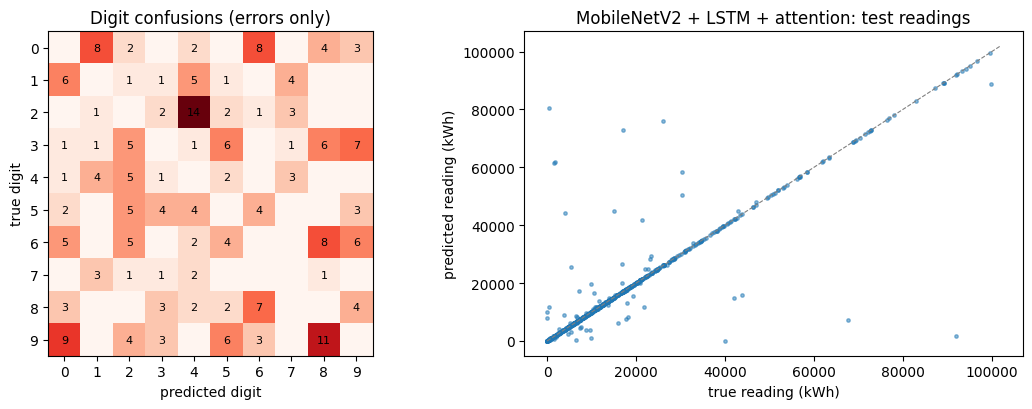

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test.ravel(), p_best.ravel()):
    cm[t, p] += 1
off = cm.copy()
np.fill_diagonal(off, 0)
im = axes[0].imshow(off, cmap="Reds")
for i in range(10):
    for j in range(10):
        if off[i, j]:
            axes[0].text(j, i, off[i, j], ha="center", va="center", fontsize=8)
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
axes[0].set_xlabel("predicted digit")
axes[0].set_ylabel("true digit")
axes[0].set_title("Digit confusions (errors only)")

axes[1].scatter(v_true, v_pred, s=6, alpha=0.5)
lim = [0, max(v_true.max(), v_pred.max()) * 1.02]
axes[1].plot(lim, lim, color="grey", ls="--", lw=0.8)
axes[1].set_xlabel("true reading (kWh)")
axes[1].set_ylabel("predicted reading (kWh)")
axes[1].set_title(f"{NAMES[BEST]}: test readings")
plt.tight_layout()
fig.savefig(FIG_DIR / "errors_confusion_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

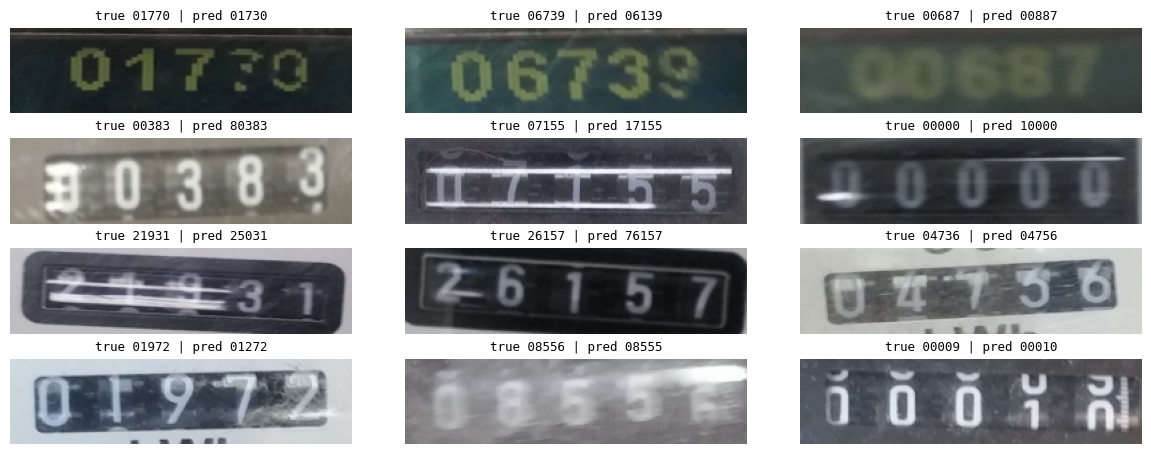

In [7]:
# một số ảnh đọc sai: nhãn thật / dự đoán
idx = np.where(wrong)[0][:12]
fig, axes = plt.subplots(4, 3, figsize=(12, 4.6))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(data["x_test"][i])
    ax.set_title(f"true {data['reading_test'][i]} | pred {''.join(map(str, p_best[i]))}", fontsize=9, family="monospace")
plt.tight_layout()
fig.savefig(FIG_DIR / "samples_errors.png", dpi=150, bbox_inches="tight")
plt.show()

- Most wrong readings have a single wrong digit (115 of 161); only 16 images have three or more wrong digits.
- 58 of the 161 wrong readings differ only in the last digit (an error below 10 kWh), which would hardly matter for a bill. At the other extreme, 54 wrong readings are off by 1,000 kWh or more because a leading digit is wrong. The median absolute error over all test images is 0 kWh, while the MAE is 1,152 kWh: a few large errors dominate MAE and RMSE.
- The most frequent confusions are between digits with similar shapes (9 read as 8, 6 as 8, 0 as 6) and between neighbouring values of a rolling wheel (9 read as 0, 0 as 1). The single most frequent confusion is 2 read as 4 (14 times).
- The examples show the main causes: strong blur, reflections or glare on the plastic cover (often over the first digit), scratches, and wheels caught between two values. In the last example (`00009` read as `00010`) the last two wheels are turning from 09 to 10; the annotation takes the lower values and the model the upper ones.
- Accuracy depends on the camera: 90.4 % of the meters photographed with the iPhone 6s are read exactly, against 78.9 % with the Samsung Galaxy J7 Prime and 75.3 % with the LG G3.

## 3. Attention maps

For each digit the attention layer gives a weight to each of the 16 image columns. The weights are obtained by calling the trained attention layer on the column states (encoder) and the 5 digit states (decoder).

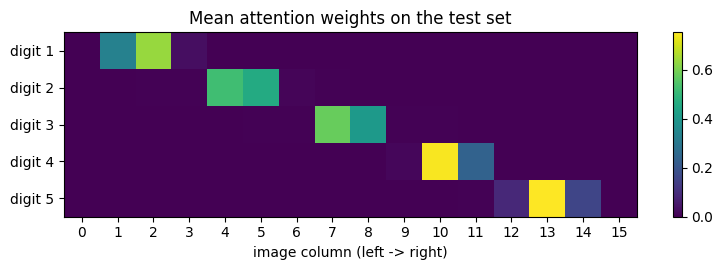

column with the largest mean weight for each digit: [2, 4, 7, 10, 13]


In [8]:
att_model = models[ATT_RUN]
sub = keras.Model(att_model.input, [att_model.get_layer("encoder_bilstm").output[0], att_model.get_layer("decoder_lstm").output])
enc_seq, dec_seq = sub.predict(data["x_test"], verbose=0)
_, w = att_model.get_layer("attention")([dec_seq, enc_seq], return_attention_scores=True)
w = np.asarray(w)  # (800 ảnh, 5 chữ số, 16 cột)

fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(w.mean(axis=0), cmap="viridis", aspect="auto")
ax.set_yticks(range(NUM_DIGITS), [f"digit {k + 1}" for k in range(NUM_DIGITS)])
ax.set_xticks(range(w.shape[2]))
ax.set_xlabel("image column (left -> right)")
ax.set_title("Mean attention weights on the test set")
fig.colorbar(im, ax=ax)
plt.tight_layout()
fig.savefig(FIG_DIR / "attention_mean.png", dpi=150, bbox_inches="tight")
plt.show()
print("column with the largest mean weight for each digit:", w.mean(axis=0).argmax(axis=1).tolist())

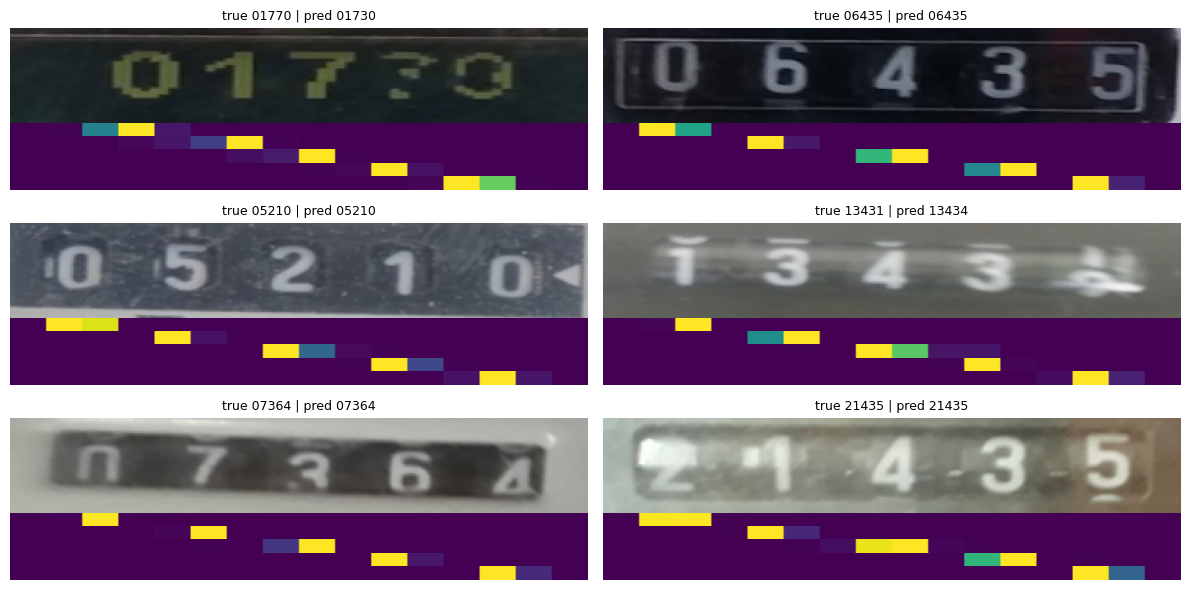

In [9]:
# attention trên từng ảnh: mỗi hàng màu là trọng số của một chữ số, kéo giãn theo chiều rộng ảnh
cols = w.shape[2]
fig, axes = plt.subplots(3, 2, figsize=(12, 6))
for ax, i in zip(axes.ravel(), [0, 100, 200, 300, 400, 500]):
    img = data["x_test"][i]
    ax.imshow(img, extent=(0, IMG_W, 64, 0))
    for k in range(NUM_DIGITS):
        row = np.repeat(w[i, k] / w[i, k].max(), IMG_W // cols)[None, :]
        ax.imshow(row, extent=(0, IMG_W, 64 + 9 * (k + 1), 64 + 9 * k), cmap="viridis", aspect="auto")
    ax.set_ylim(64 + 9 * NUM_DIGITS, 0)
    ax.set_title(f"true {data['reading_test'][i]} | pred {''.join(map(str, pred[(ATT_RUN, 'test')][i]))}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "samples_attention.png", dpi=150, bbox_inches="tight")
plt.show()

- On average each digit puts almost all of its attention on two or three neighbouring columns, and the most attended column moves from left to right: columns 2, 4, 7, 10 and 13 for digits 1 to 5. The 16 columns cover the counter from left to right, so the decoder has learned where each digit is printed, although it was never given the digit positions (the training labels contain only the five digit values).
- On single images the attention follows the actual position of the digits, which differs between meter types (digits closer together or further apart).
- This is the main difference from Task 2. There the useful information was spread over the whole day, so the attention had little to choose. Here each output digit depends on one small part of the input, and attention raises the share of exactly read meters from 29.6 % to 79.9 %.

## Summary

- Main model: MobileNetV2 encoder (pretrained on ImageNet, then fine-tuned) + bidirectional LSTM encoder + LSTM decoder with dot-product attention.
- Test set (800 meters): 79.9 % of the meters read exactly and 94.3 % of the digits correct; for the reading value R² 0.841, NSE 0.831, MAE 1,152 kWh, RMSE 7,078 kWh (median absolute error 0 kWh).
- Attention is essential here (29.6 % -> 79.9 % exact readings) and its weights show that each digit is read from its own place in the image. Transfer learning is essential too: a CNN trained from scratch on the 800 training images reads 0.8 % of the meters.
- The remaining errors come from blur, reflections, scratches and wheels between two values; the last digit is the hardest.
- Limits: one run per model (one random seed), 800 training images from a single warehouse, and the counter position is taken from the annotation; in a real application it would first have to be detected in the photo.